In [1]:
# Library imports
import mne
import numpy as np
import pandas as pd
import os
import time
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
 
from scipy.signal import welch
from scipy.stats import skew, kurtosis
 
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_curve, auc,
                             f1_score, recall_score, precision_score)
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
 
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv1D, LSTM, Dense, Dropout,
                                     MaxPooling1D, BatchNormalization)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [2]:
# SEIZURE ANNOTATION MAP
seizure_map = {
    # Subject 01
    'chb01_03.edf': [(2996, 3036)],
    'chb01_04.edf': [(1467, 1494)],
    'chb01_15.edf': [(1732, 1772)],
    'chb01_16.edf': [(1015, 1066)],
    'chb01_18.edf': [(1720, 1810)],
    'chb01_21.edf': [(327, 420)],
    'chb01_26.edf': [(1862, 1963)],
    # Subject 02
    'chb02_16.edf': [(130, 212)],
    'chb02_19.edf': [(3369, 3378)],
    # Subject 03
    'chb03_01.edf': [(362, 414)],
    'chb03_02.edf': [(731, 796)],
    'chb03_03.edf': [(432, 501)],
    'chb03_04.edf': [(2162, 2214)],
    'chb03_34.edf': [(1982, 2029)],
    'chb03_35.edf': [(2592, 2656)],
    'chb03_36.edf': [(1725, 1778)],
    # Subject 04
    'chb04_05.edf': [(6186, 6211)],
    'chb04_08.edf': [(6477, 6510)],
    'chb04_28.edf': [(1679, 1781)],
    # Subject 05
    'chb05_06.edf': [(417, 532)],
    'chb05_13.edf': [(1086, 1196)],
    'chb05_16.edf': [(2317, 2413)],
    'chb05_17.edf': [(2451, 2571)],
    # Subject 06
    'chb06_01.edf': [(1724, 1738)],
    'chb06_04.edf': [(327, 347)],
    'chb06_09.edf': [(12500, 12516)],
}
 
SFREQ      = 256          # Sampling rate (Hz)
WINDOW_SEC = 5            # Window length in seconds
WIN_SAMPLES = SFREQ * WINDOW_SEC  # = 1280 samples per window
 
# EEG frequency bands (Hz)
BANDS = {
    'delta': (0.5, 4),
    'theta': (4, 8),
    'alpha': (8, 13),
    'beta':  (13, 30),
}

In [3]:
# FEATURE EXTRACTION
def extract_features(window):
    """
    Extract handcrafted EEG features from a single window.
 
    Parameters
    ----------
    window : np.ndarray, shape (n_channels, n_samples)
 
    Returns
    -------
    features : np.ndarray, 1-D feature vector
    """
    features = []
    n_channels = window.shape[0]
 
    for ch in range(n_channels):
        sig = window[ch]
 
        # Statistical features
        features.append(np.mean(sig))
        features.append(np.std(sig))
        features.append(np.var(sig))
        features.append(float(skew(sig)))
        features.append(float(kurtosis(sig)))
 
        # Band-power features (Welch PSD)
        freqs, psd = welch(sig, fs=SFREQ, nperseg=min(256, len(sig)))
        total_power = np.trapz(psd, freqs) + 1e-10          
 
        for band_name, (lo, hi) in BANDS.items():
            idx = np.logical_and(freqs >= lo, freqs <= hi)
            band_power = np.trapz(psd[idx], freqs[idx])
            features.append(band_power)
            features.append(band_power / total_power)        
 
    return np.array(features, dtype=np.float32)


In [4]:
# PROCESSING of Data
def process_subject(sub_path, subject_files):
    """
    Load, filter, window and label EEG for one subject in chronological order.
 
    Returns raw windows (for DL) and feature vectors (for ML), plus labels.
    """
    X_raw_list, X_feat_list, y_list = [], [], []
 
    for file in sorted(subject_files):           
        file_path = os.path.join(sub_path, file)
        if not os.path.exists(file_path):
            continue
 
        print(f"  Loading {file} ...")
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)
        raw.filter(0.5, 40.0, fir_design='firwin', verbose=False)
 
        # Keep only the first 23 channels for consistency
        raw.pick(raw.ch_names[:23])
        data = raw.get_data()                    
 
        n_windows = data.shape[1] // WIN_SAMPLES
        seizures   = seizure_map.get(file, [])
 
        for i in range(n_windows):
            start  = i * WIN_SAMPLES
            end    = start + WIN_SAMPLES
            window = data[:, start:end]          # (23, 1280)
 
            # Label: seizure if window start falls inside any seizure interval
            sec_start = start / SFREQ
            label = 0
            for s_start, s_end in seizures:
                if s_start <= sec_start <= s_end:
                    label = 1
                    break
 
            X_raw_list.append(window)
            X_feat_list.append(extract_features(window))
            y_list.append(label)
 
    X_raw  = np.array(X_raw_list,  dtype=np.float32)   # (N, 23, 1280)
    X_feat = np.array(X_feat_list, dtype=np.float32)   # (N, n_features)
    y      = np.array(y_list,      dtype=np.int32)
 
    return X_raw, X_feat, y

In [ ]:
# DATA LOADING
data_dir = r"your data files path"
subjects  = ['chb01', 'chb02', 'chb03', 'chb04', 'chb05', 'chb06']
 
all_X_raw, all_X_feat, all_y = [], [], []
subject_sizes = []   # used for learning-curve
 
for sub in subjects:
    sub_path = os.path.join(data_dir, sub)
    if not os.path.isdir(sub_path):
        print(f"[SKIP] {sub} not found — skipping.")
        continue
 
    sub_files = [f for f in os.listdir(sub_path)
                 if f.endswith('.edf') and f in seizure_map]
 
    if not sub_files:
        print(f"[SKIP] No labelled files found for {sub}.")
        continue
 
    print(f"\nProcessing {sub} ({len(sub_files)} files)…")
    X_raw, X_feat, y = process_subject(sub_path, sub_files)
 
    n_seiz = y.sum()
    print(f"  → {len(y)} windows | {n_seiz} seizure | {len(y)-n_seiz} normal")
 
    all_X_raw.append(X_raw)
    all_X_feat.append(X_feat)
    all_y.append(y)
    subject_sizes.append(len(y))
 
# Stack everything in chronological order
X_raw_all  = np.vstack(all_X_raw)              # (N, 23, 1280)
X_feat_all = np.vstack(all_X_feat)             # (N, n_features)
y_all      = np.concatenate(all_y)             # (N,)
 
print(f"\n{'='*55}")
print(f"Total windows   : {len(y_all)}")
print(f"Seizure windows : {y_all.sum()}  ({y_all.mean()*100:.2f}%)")
print(f"Normal  windows : {(y_all==0).sum()}")
print(f"Feature vector  : {X_feat_all.shape[1]} features per window")
print(f"{'='*55}\n")

split_idx = int(len(y_all) * 0.80)
 
X_feat_train, X_feat_test = X_feat_all[:split_idx], X_feat_all[split_idx:]
y_train,       y_test      = y_all[:split_idx],      y_all[split_idx:]
 
# DL data: swap axes → (N, 1280, 23)  [time-steps, channels]
X_dl_all   = np.swapaxes(X_raw_all, 1, 2)
X_dl_train = X_dl_all[:split_idx]
X_dl_test  = X_dl_all[split_idx:]


Processing chb01 (7 files)…
  Loading chb01_03.edf ...
  Loading chb01_04.edf ...
  Loading chb01_15.edf ...
  Loading chb01_16.edf ...
  Loading chb01_18.edf ...
  Loading chb01_21.edf ...
  Loading chb01_26.edf ...
  → 4785 windows | 90 seizure | 4695 normal

Processing chb02 (2 files)…
  Loading chb02_16.edf ...
  Loading chb02_19.edf ...
  → 911 windows | 19 seizure | 892 normal

Processing chb03 (7 files)…
  Loading chb03_01.edf ...
  Loading chb03_02.edf ...
  Loading chb03_03.edf ...
  Loading chb03_04.edf ...
  Loading chb03_34.edf ...
  Loading chb03_35.edf ...
  Loading chb03_36.edf ...
  → 5040 windows | 80 seizure | 4960 normal
[SKIP] chb04 not found — skipping.
[SKIP] chb05 not found — skipping.
[SKIP] chb06 not found — skipping.

Total windows   : 10736
Seizure windows : 189  (1.76%)
Normal  windows : 10547
Feature vector  : 299 features per window



In [6]:
# FEATURE SCALING
scaler = StandardScaler()
X_feat_train_sc = scaler.fit_transform(X_feat_train)
X_feat_test_sc  = scaler.transform(X_feat_test)
 
# Imbalance ratio for class weighting
pos = int(y_train.sum())
neg = int((y_train == 0).sum())
scale_weight = neg / (pos + 1e-10)
print(f"Class imbalance ratio (neg/pos): {scale_weight:.1f}:1\n")

Class imbalance ratio (neg/pos): 54.1:1



In [7]:
# evaluation report
def evaluate_model(name, y_true, y_pred, y_prob=None):
    print(f"\n{'='*55}")
    print(f"  {name} — Evaluation Results")
    print(f"{'='*55}")
    print(classification_report(y_true, y_pred,
                                target_names=['Normal', 'Seizure'],
                                digits=4))
 
    # Clinical metrics
    TP = int(((y_pred == 1) & (y_true == 1)).sum())
    FN = int(((y_pred == 0) & (y_true == 1)).sum())
    FP = int(((y_pred == 1) & (y_true == 0)).sum())
    TN = int(((y_pred == 0) & (y_true == 0)).sum())
 
    sensitivity = TP / (TP + FN + 1e-10)
    specificity = TN / (TN + FP + 1e-10)
    FAR         = FP / (FP + TN + 1e-10)
 
    print(f"  Sensitivity (Recall) : {sensitivity:.4f}  ← % seizures caught")
    print(f"  Specificity          : {specificity:.4f}")
    print(f"  False Alarm Rate     : {FAR:.4f}  ← % normals wrongly flagged")
 
    roc_auc = None
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        roc_auc = auc(fpr, tpr)
        print(f"  AUC-ROC              : {roc_auc:.4f}")
 
    return sensitivity, FAR, roc_auc

In [8]:
# confusion matrix plot
def plot_cm(y_true, y_pred, title, ax):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Normal', 'Seizure'],
                yticklabels=['Normal', 'Seizure'])
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

In [11]:
# MODEL 1: XGBoost (with class weighting)

xgb = XGBClassifier(
    scale_pos_weight=scale_weight,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
 
t0 = time.time()
xgb.fit(X_feat_train_sc, y_train)
xgb_train_time = time.time() - t0
 
# Inference latency + throughput
t0 = time.time()
xgb_preds = xgb.predict(X_feat_test_sc)
xgb_inf_time = time.time() - t0
xgb_latency   = (xgb_inf_time / len(X_feat_test_sc)) * 1000   # ms per window
xgb_throughput = len(X_feat_test_sc) / xgb_inf_time            # windows/sec
 
xgb_prob = xgb.predict_proba(X_feat_test_sc)[:, 1]
xgb_sens, xgb_FAR, xgb_auc = evaluate_model(
    "XGBoost", y_test, xgb_preds, xgb_prob)
 
print(f"\n  Train time : {xgb_train_time:.2f}s")
print(f"  Latency    : {xgb_latency:.4f} ms/window")
print(f"  Throughput : {xgb_throughput:.1f} windows/sec")


  XGBoost — Evaluation Results
              precision    recall  f1-score   support

      Normal     0.9986    0.9929    0.9957      2115
     Seizure     0.6667    0.9091    0.7692        33

    accuracy                         0.9916      2148
   macro avg     0.8326    0.9510    0.8825      2148
weighted avg     0.9935    0.9916    0.9923      2148

  Sensitivity (Recall) : 0.9091  ← % seizures caught
  Specificity          : 0.9929
  False Alarm Rate     : 0.0071  ← % normals wrongly flagged
  AUC-ROC              : 0.9977

  Train time : 3.13s
  Latency    : 0.0014 ms/window
  Throughput : 716165.7 windows/sec


In [13]:
# MODEL 2: Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

t0 = time.time()
rf.fit(X_feat_train_sc, y_train)
rf_train_time = time.time() - t0

# measure latency on predict_proba since that's the actual inference path
t0 = time.time()
rf_prob = rf.predict_proba(X_feat_test_sc)[:, 1]
rf_inf_time   = time.time() - t0
rf_latency    = (rf_inf_time / len(X_feat_test_sc)) * 1000
rf_throughput = len(X_feat_test_sc) / rf_inf_time

# Threshold calibration on validation fold
val_split_ml = int(len(X_feat_train_sc) * 0.9)
X_val_ml = X_feat_train_sc[val_split_ml:]
y_val_ml = y_train[val_split_ml:]

rf_val_prob = rf.predict_proba(X_val_ml)[:, 1]

best_thresh_rf, best_f1_rf = 0.5, 0.0
for thresh in np.linspace(0.05, 0.90, 18):
    preds_t = (rf_val_prob > thresh).astype(int)
    f1_t = f1_score(y_val_ml, preds_t, zero_division=0)
    if f1_t > best_f1_rf:
        best_f1_rf     = f1_t
        best_thresh_rf = thresh

print(f"RF Best threshold (val F1={best_f1_rf:.4f}): {best_thresh_rf:.2f}")

rf_preds = (rf_prob > best_thresh_rf).astype(int)
rf_sens, rf_FAR, rf_auc = evaluate_model(
    "Random Forest (threshold-tuned)", y_test, rf_preds, rf_prob)

print(f"\n  Train time : {rf_train_time:.2f}s")
print(f"  Latency    : {rf_latency:.4f} ms/window")
print(f"  Throughput : {rf_throughput:.1f} windows/sec")

RF Best threshold (val F1=1.0000): 0.05

  Random Forest (threshold-tuned) — Evaluation Results
              precision    recall  f1-score   support

      Normal     1.0000    0.9735    0.9866      2115
     Seizure     0.3708    1.0000    0.5410        33

    accuracy                         0.9739      2148
   macro avg     0.6854    0.9868    0.7638      2148
weighted avg     0.9903    0.9739    0.9797      2148

  Sensitivity (Recall) : 1.0000  ← % seizures caught
  Specificity          : 0.9735
  False Alarm Rate     : 0.0265  ← % normals wrongly flagged
  AUC-ROC              : 0.9978

  Train time : 1.29s
  Latency    : 0.0438 ms/window
  Throughput : 22851.4 windows/sec


In [14]:
# MODEL 3: CNN-LSTM (fixed)
MAX_WEIGHT = 20.0
cnn_class_weight = min(scale_weight, MAX_WEIGHT)
class_weight_dict = {0: 1.0, 1: cnn_class_weight}
print(f"CNN-LSTM class weight for seizure class: {cnn_class_weight:.1f}:1")

model_dl = Sequential([
    tf.keras.layers.Input(shape=(WIN_SAMPLES, 23)),
    Conv1D(filters=64, kernel_size=7, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Conv1D(filters=128, kernel_size=5, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    LSTM(128, return_sequences=False),
    Dropout(0.4),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
], name='CNN_LSTM')

model_dl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Recall(name='sensitivity'),
             tf.keras.metrics.Precision(name='precision')]
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5,
                  mode='min', restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

t0 = time.time()
history = model_dl.fit(
    X_dl_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)
dl_train_time = time.time() - t0

# Threshold calibration on validation fold
val_split_idx = int(len(X_dl_train) * 0.9)
X_val_dl = X_dl_train[val_split_idx:]
y_val_dl = y_train[val_split_idx:]

val_probs = model_dl.predict(X_val_dl, verbose=0).flatten()

best_thresh, best_f1 = 0.5, 0.0
for thresh in np.linspace(0.05, 0.90, 18):
    preds_t = (val_probs > thresh).astype(int)
    f1_t = f1_score(y_val_dl, preds_t, zero_division=0)
    if f1_t > best_f1:
        best_f1      = f1_t
        best_thresh  = thresh

print(f"Best threshold (val F1 = {best_f1:.4f}): {best_thresh:.2f}")

t0 = time.time()
dl_prob  = model_dl.predict(X_dl_test, verbose=0).flatten()
dl_inf_time   = time.time() - t0
dl_preds      = (dl_prob > best_thresh).astype(int)
dl_latency    = (dl_inf_time / len(X_dl_test)) * 1000
dl_throughput = len(X_dl_test) / dl_inf_time

dl_sens, dl_FAR, dl_auc = evaluate_model(
    "CNN-LSTM (fixed)", y_test, dl_preds, dl_prob)

print(f"\n  Train time : {dl_train_time:.2f}s")
print(f"  Threshold  : {best_thresh:.2f}")
print(f"  Latency    : {dl_latency:.4f} ms/window")
print(f"  Throughput : {dl_throughput:.1f} windows/sec")

CNN-LSTM class weight for seizure class: 20.0:1
Epoch 1/30
121/121 ━━━━━━━━━━━━━━━━━━━━ 69s 524ms/step - accuracy: 0.9486 - loss: 0.8118 - precision: 0.0803 - sensitivity: 0.1644 - val_accuracy: 0.9884 - val_loss: 0.1361 - val_precision: 0.0000e+00 - val_sensitivity: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/30
121/121 ━━━━━━━━━━━━━━━━━━━━ 62s 512ms/step - accuracy: 0.8709 - loss: 0.4855 - precision: 0.1026 - sensitivity: 0.7534 - val_accuracy: 0.9884 - val_loss: 0.0639 - val_precision: 0.0000e+00 - val_sensitivity: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
121/121 ━━━━━━━━━━━━━━━━━━━━ 72s 597ms/step - accuracy: 0.9140 - loss: 0.3870 - precision: 0.1535 - sensitivity: 0.7877 - val_accuracy: 0.9884 - val_loss: 0.0634 - val_precision: 0.0000e+00 - val_sensitivity: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/30
121/121 ━━━━━━━━━━━━━━━━━━━━ 74s 611ms/step - accuracy: 0.9538 - loss: 0.4232 - precision: 0.2433 - sensitivity: 0.6849 - val_accuracy: 0.9884 - val_loss: 0.4861 - val_precisio

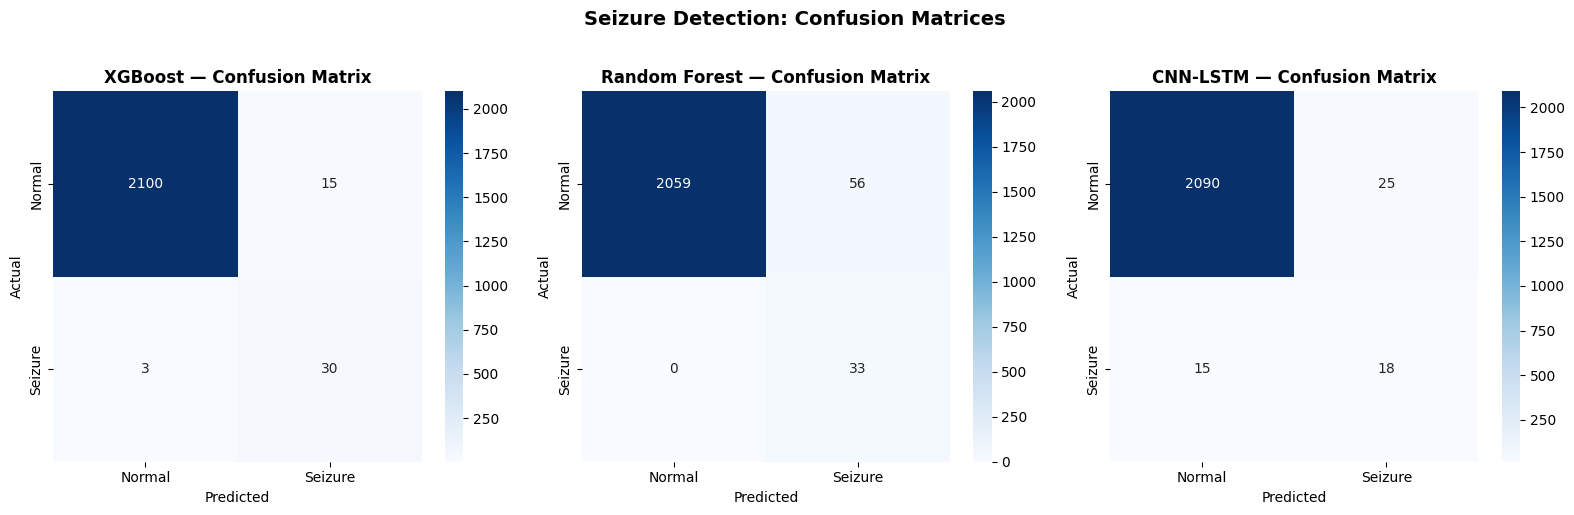

Saved: fig1_confusion_matrices.png


In [15]:
# VISUALISATION 1: Confusion Matrices (all 3 models)  ← FIX 7
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
plot_cm(y_test, xgb_preds,  "XGBoost — Confusion Matrix",    axes[0])
plot_cm(y_test, rf_preds,   "Random Forest — Confusion Matrix", axes[1])
plot_cm(y_test, dl_preds,   "CNN-LSTM — Confusion Matrix",   axes[2])
plt.suptitle("Seizure Detection: Confusion Matrices", fontsize=14,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("fig1_confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig1_confusion_matrices.png")

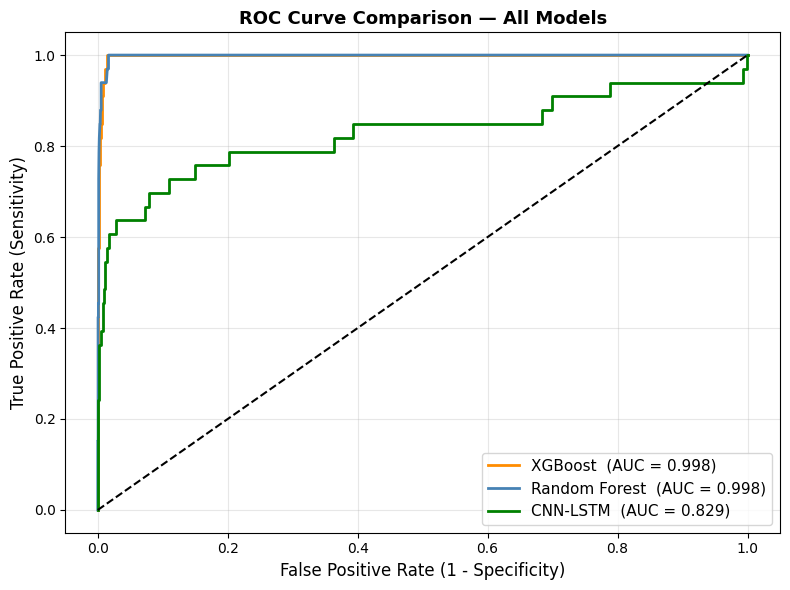

Saved: fig2_roc_comparison.png


In [16]:
# VISUALISATION 2: ROC Curves — all 3 models on one plot
fig, ax = plt.subplots(figsize=(8, 6))
 
for name, prob, color in [
    ("XGBoost",       xgb_prob, 'darkorange'),
    ("Random Forest", rf_prob,  'steelblue'),
    ("CNN-LSTM",      dl_prob,  'green'),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"{name}  (AUC = {roc_val:.3f})")
 
ax.plot([0, 1], [0, 1], 'k--', lw=1.5)
ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=12)
ax.set_title("ROC Curve Comparison — All Models", fontsize=13,
             fontweight='bold')
ax.legend(loc="lower right", fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("fig2_roc_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig2_roc_comparison.png")

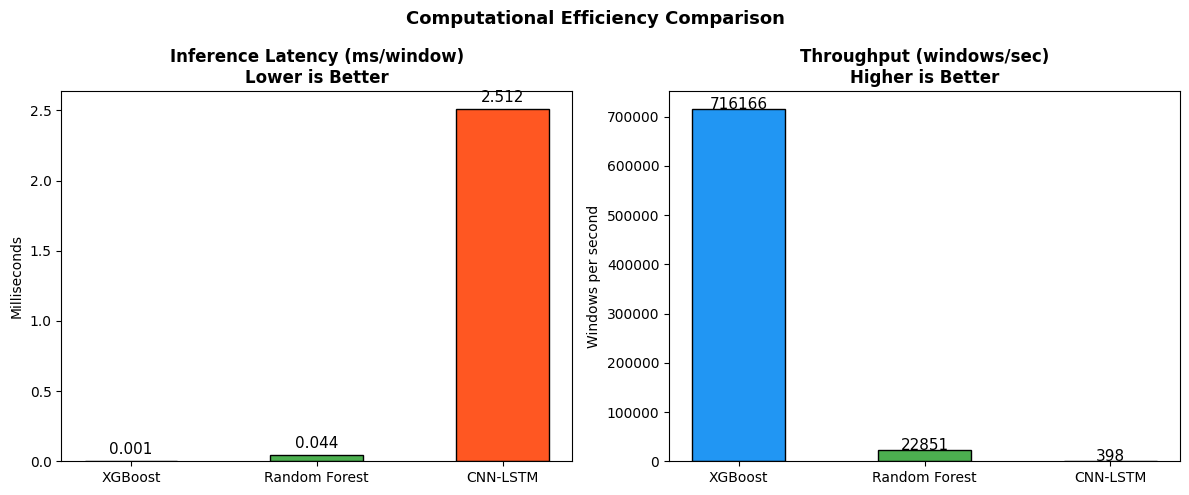

Saved: fig3_latency_throughput.png


In [17]:
# VISUALISATION 3: Inference Latency & Throughput
models_list = ['XGBoost', 'Random Forest', 'CNN-LSTM']
latencies   = [xgb_latency,  rf_latency,  dl_latency]
throughputs = [xgb_throughput, rf_throughput, dl_throughput]
 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
 
colors = ['#2196F3', '#4CAF50', '#FF5722']
 
axes[0].bar(models_list, latencies, color=colors, edgecolor='black', width=0.5)
axes[0].set_title("Inference Latency (ms/window)\nLower is Better",
                  fontsize=12, fontweight='bold')
axes[0].set_ylabel("Milliseconds")
for i, v in enumerate(latencies):
    axes[0].text(i, v + 0.05, f"{v:.3f}", ha='center', fontsize=11)
 
axes[1].bar(models_list, throughputs, color=colors, edgecolor='black', width=0.5)
axes[1].set_title("Throughput (windows/sec)\nHigher is Better",
                  fontsize=12, fontweight='bold')
axes[1].set_ylabel("Windows per second")
for i, v in enumerate(throughputs):
    axes[1].text(i, v + 1, f"{v:.0f}", ha='center', fontsize=11)
 
plt.suptitle("Computational Efficiency Comparison", fontsize=13,
             fontweight='bold')
plt.tight_layout()
plt.savefig("fig3_latency_throughput.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig3_latency_throughput.png")

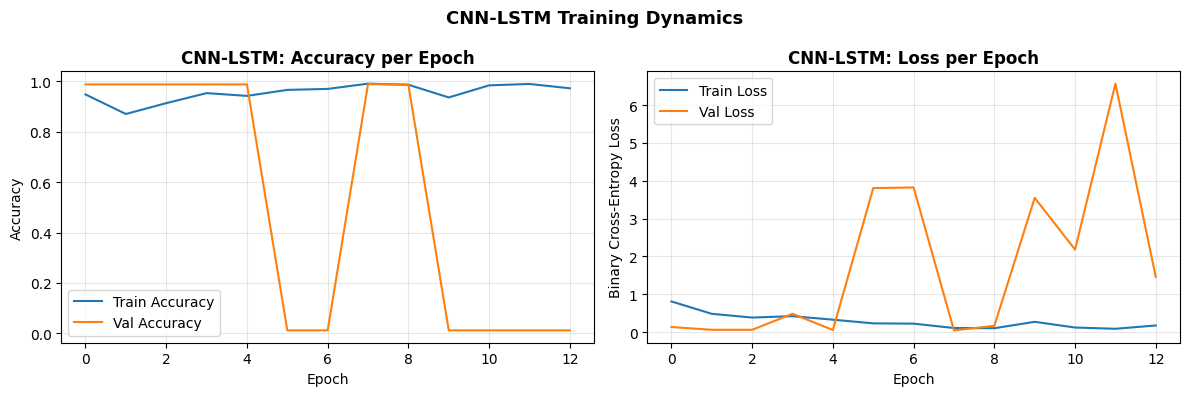

Saved: fig4_cnn_lstm_training.png


In [18]:
# VISUALISATION 4: CNN-LSTM Training Curves (accuracy + loss)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
 
axes[0].plot(history.history['accuracy'],     label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
axes[0].set_title("CNN-LSTM: Accuracy per Epoch", fontweight='bold')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)
 
axes[1].plot(history.history['loss'],     label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Val Loss')
axes[1].set_title("CNN-LSTM: Loss per Epoch", fontweight='bold')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)
 
plt.suptitle("CNN-LSTM Training Dynamics", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("fig4_cnn_lstm_training.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig4_cnn_lstm_training.png")


Generating learning curves (this may take a few minutes) …


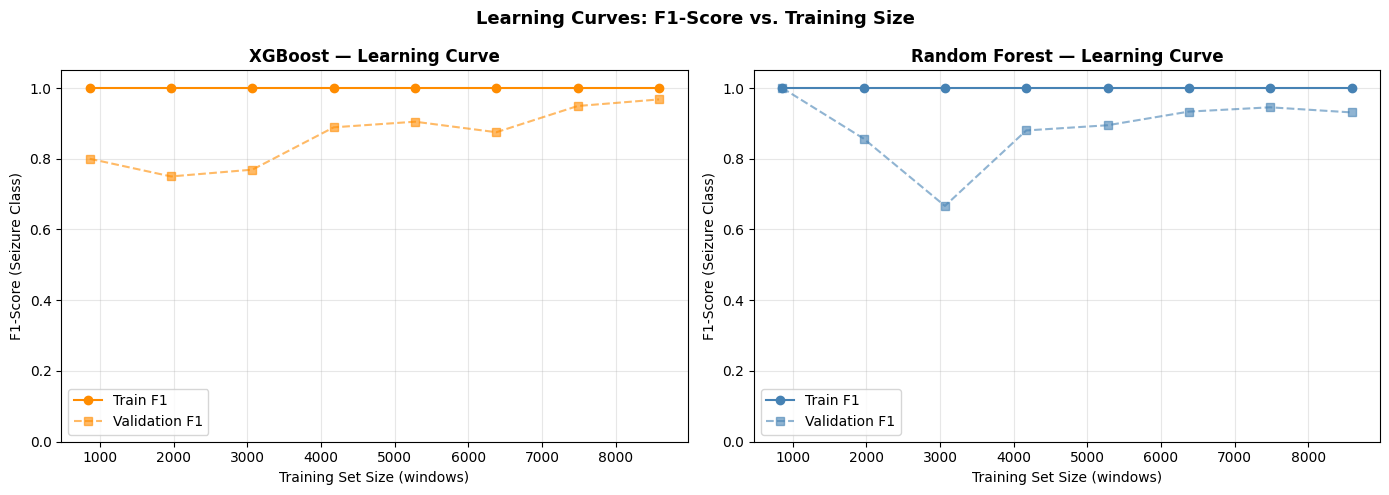

Saved: fig5_learning_curves.png


In [19]:
# VISUALISATION 5: PROPER LEARNING CURVES
print("\nGenerating learning curves (this may take a few minutes) …")
 
train_sizes = np.linspace(0.1, 1.0, 8)
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
for idx, (clf, name, color) in enumerate([
    (XGBClassifier(scale_pos_weight=scale_weight, n_estimators=100,
                   use_label_encoder=False, eval_metric='logloss',
                   random_state=42, n_jobs=-1),
     "XGBoost", "darkorange"),
    (RandomForestClassifier(n_estimators=100, class_weight='balanced',
                            random_state=42, n_jobs=-1),
     "Random Forest", "steelblue"),
]):
    sizes, train_f1s, val_f1s = [], [], []
 
    for frac in train_sizes:
        n = max(int(len(X_feat_train_sc) * frac), 50)
        Xtr = X_feat_train_sc[:n]
        ytr = y_train[:n]
 
        if ytr.sum() < 2:         
            continue
 
        # Inner split for this fraction
        Xtr2, Xv2, ytr2, yv2 = train_test_split(
            Xtr, ytr, test_size=0.2, random_state=42,
            stratify=ytr if ytr.sum() >= 2 else None)
 
        clf.fit(Xtr2, ytr2)
 
        train_f1s.append(f1_score(ytr2, clf.predict(Xtr2),
                                  zero_division=0))
        val_f1s.append(f1_score(yv2,  clf.predict(Xv2),
                                zero_division=0))
        sizes.append(n)
 
    axes[idx].plot(sizes, train_f1s, 'o-', label='Train F1', color=color)
    axes[idx].plot(sizes, val_f1s,   's--', label='Validation F1',
                   color=color, alpha=0.6)
    axes[idx].set_title(f"{name} — Learning Curve", fontweight='bold')
    axes[idx].set_xlabel("Training Set Size (windows)")
    axes[idx].set_ylabel("F1-Score (Seizure Class)")
    axes[idx].legend(); axes[idx].grid(alpha=0.3)
    axes[idx].set_ylim([0, 1.05])
 
plt.suptitle("Learning Curves: F1-Score vs. Training Size",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("fig5_learning_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig5_learning_curves.png")

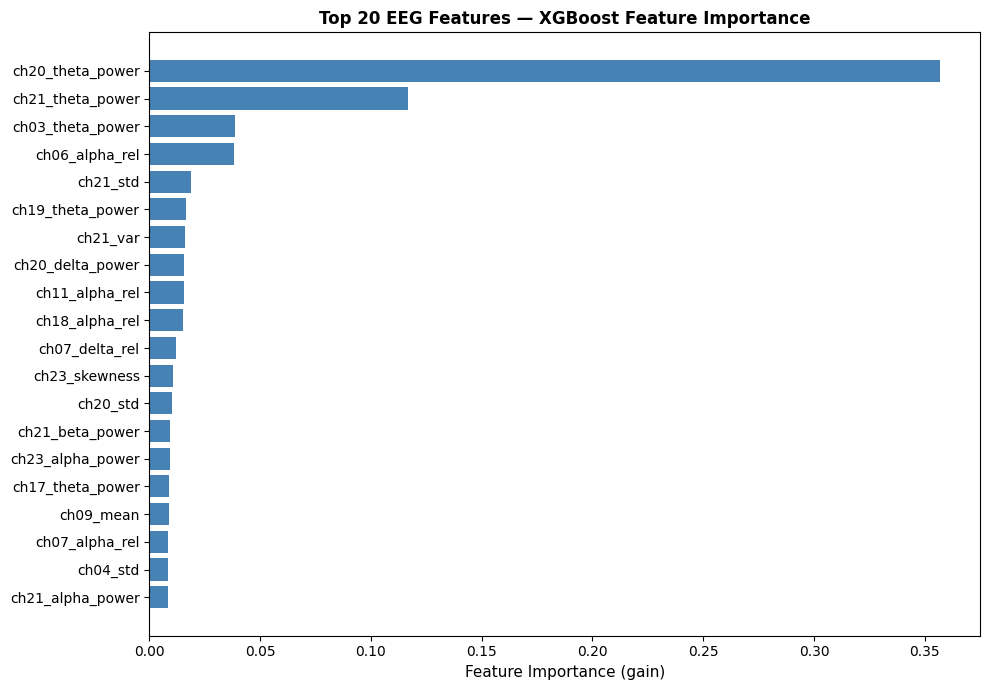

Saved: fig6_feature_importance.png


In [20]:
# VISUALISATION 6: XGBoost Feature Importance (meaningful feature names)
feature_names = []
stat_names = ['mean', 'std', 'var', 'skewness', 'kurtosis']
band_names  = list(BANDS.keys())
 
for ch in range(23):
    for s in stat_names:
        feature_names.append(f"ch{ch+1:02d}_{s}")
    for b in band_names:
        feature_names.append(f"ch{ch+1:02d}_{b}_power")
        feature_names.append(f"ch{ch+1:02d}_{b}_rel")
 
importances = xgb.feature_importances_
top_idx     = np.argsort(importances)[::-1][:20]
 
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh([feature_names[i] for i in top_idx[::-1]],
        importances[top_idx[::-1]],
        color='steelblue')
ax.set_xlabel("Feature Importance (gain)", fontsize=11)
ax.set_title("Top 20 EEG Features — XGBoost Feature Importance",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig("fig6_feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig6_feature_importance.png")

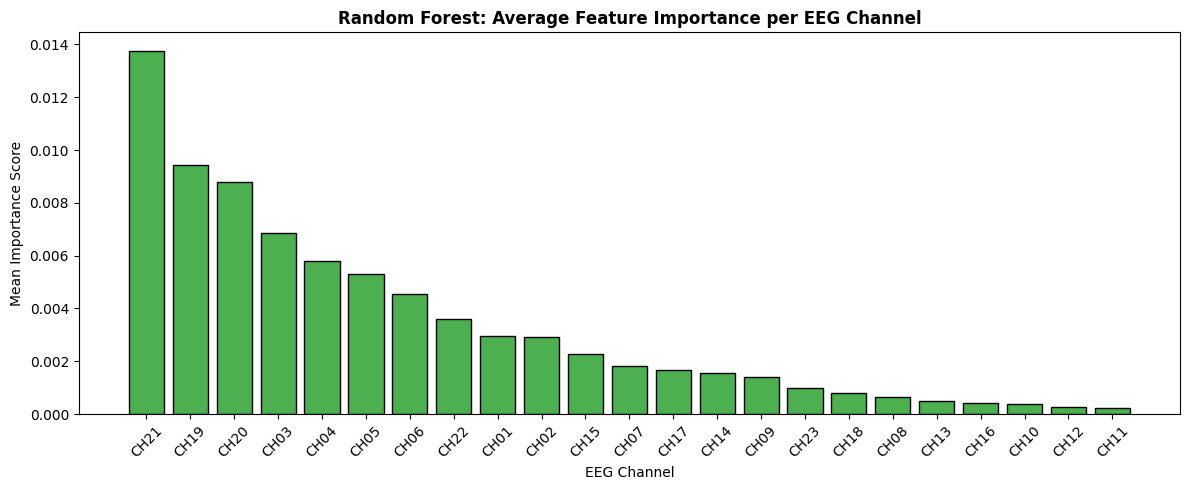

Saved: fig7_rf_channel_importance.png


In [21]:
# VISUALISATION 7: Random Forest Channel Importance
rf_importances = rf.feature_importances_
# Average importance per channel
ch_importance = np.zeros(23)
n_feat_per_ch = len(feature_names) // 23
for ch in range(23):
    start_f = ch * n_feat_per_ch
    end_f   = start_f + n_feat_per_ch
    ch_importance[ch] = rf_importances[start_f:end_f].mean()
 
ch_labels = [f"CH{i+1:02d}" for i in range(23)]
sorted_idx = np.argsort(ch_importance)[::-1]
 
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar([ch_labels[i] for i in sorted_idx],
       ch_importance[sorted_idx],
       color='#4CAF50', edgecolor='black')
ax.set_title("Random Forest: Average Feature Importance per EEG Channel",
             fontsize=12, fontweight='bold')
ax.set_xlabel("EEG Channel")
ax.set_ylabel("Mean Importance Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("fig7_rf_channel_importance.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: fig7_rf_channel_importance.png")

In [22]:
# FINAL SUMMARY TABLE
results = {
    "Model": ["XGBoost", "Random Forest", "CNN-LSTM"],
    "Accuracy": [
        accuracy_score(y_test, xgb_preds),
        accuracy_score(y_test, rf_preds),
        accuracy_score(y_test, dl_preds),
    ],
    "F1 (Seizure)": [
        f1_score(y_test, xgb_preds, pos_label=1, zero_division=0),
        f1_score(y_test, rf_preds,  pos_label=1, zero_division=0),
        f1_score(y_test, dl_preds,  pos_label=1, zero_division=0),
    ],
    "Sensitivity": [xgb_sens,  rf_sens,  dl_sens],
    "FAR":         [xgb_FAR,   rf_FAR,   dl_FAR],
    "AUC-ROC":     [xgb_auc,   rf_auc,   dl_auc],
    "Latency(ms)": [xgb_latency,  rf_latency,  dl_latency],
    "Throughput(w/s)": [xgb_throughput, rf_throughput, dl_throughput],
    "Train Time(s)":   [xgb_train_time, rf_train_time, dl_train_time],
}
 
df_results = pd.DataFrame(results)
pd.set_option('display.float_format', '{:.4f}'.format)
print("\n" + "="*80)
print("  FINAL MODEL COMPARISON TABLE")
print("="*80)
print(df_results.to_string(index=False))
print("="*80)
 
# Save results table to CSV
df_results.to_csv("model_comparison_results.csv", index=False)
print("\nSaved: model_comparison_results.csv")


  FINAL MODEL COMPARISON TABLE
        Model  Accuracy  F1 (Seizure)  Sensitivity    FAR  AUC-ROC  Latency(ms)  Throughput(w/s)  Train Time(s)
      XGBoost    0.9916        0.7692       0.9091 0.0071   0.9977       0.0014      716165.7386         3.1305
Random Forest    0.9739        0.5410       1.0000 0.0265   0.9978       0.0438       22851.4450         1.2881
     CNN-LSTM    0.9814        0.4737       0.5455 0.0118   0.8287       2.5124         398.0282       897.8605

Saved: model_comparison_results.csv


In [23]:
# SAVEING MODELS
import joblib
 
joblib.dump(xgb,    'seizure_xgb_model.pkl')
joblib.dump(rf,     'seizure_rf_model.pkl')
joblib.dump(scaler, 'seizure_scaler.pkl')       # ← save scaler too!
model_dl.save('seizure_cnn_lstm.keras')         # ← native Keras format
 
print("\nAll models and scaler saved successfully.")
print("Files: seizure_xgb_model.pkl | seizure_rf_model.pkl |"
      " seizure_scaler.pkl | seizure_cnn_lstm.keras")
 


All models and scaler saved successfully.
Files: seizure_xgb_model.pkl | seizure_rf_model.pkl | seizure_scaler.pkl | seizure_cnn_lstm.keras
